# Statistical Learning I Project: Handwritten Digit Classification
### Kaggle Digit Recognizer (MNIST) — EDA, statistical learning, diagnostics and model selection

**Project objective:** classify handwritten images into one of ten classes (digits 0–9), compare statistical learning methods, diagnose errors and select a model using validation data.

This notebook is written as a guided project. Each section explains **what we are doing, why we are doing it, and how to interpret the output**. Run the cells from top to bottom in Google Colab.

**Main principles**
- Use a held-out validation set to estimate generalisation performance.
- Fit preprocessing only on training folds through `Pipeline` to avoid data leakage.
- Compare models on the same validation observations.
- Select hyperparameters using cross-validation, not the Kaggle test set.
- Report both predictive performance and model limitations.

> Important: Kaggle's `test.csv` has no labels. We therefore cannot calculate its accuracy locally. The honest test of model performance in this project is the held-out validation set. The Kaggle file is used only after model selection to create a submission.

## 0. Project map and connection to the syllabus

| Project stage | What we do | Statistical Learning I concepts |
|---|---|---|
| Problem definition | Identify the response and predictors | Classification; prediction |
| Data preparation | Reshape pixels, inspect quality, scale | Data representation |
| EDA | Class counts, digit images, pixel summaries | Exploratory data analysis |
| Baseline | Majority-class classifier | Benchmarking |
| Statistical models | Logistic regression, LDA | Multivariate logistic regression; Fisher/LDA ideas |
| Neighbour method | k-nearest neighbours | k-NN classifier; model complexity |
| Tree/ensemble | Decision tree and random forest | CART; ensemble learning |
| Margin method | Linear/RBF SVM | Maximum-margin classifiers; kernel SVM |
| Penalisation | L1 logistic regression | Lasso/soft thresholding idea; variable selection |
| Model selection | Cross-validation and tuning | Model selection; bias–variance trade-off |
| Diagnostics | Confusion matrix, class metrics, error inspection | Prediction diagnostics |
| Final model | Refit and make Kaggle predictions | Prediction |

**Scope note:** This is a classification problem, so regression topics such as spline regression, GAMs, tensor regression and functional regression are not forced into the analysis. A small neural-network extension is listed at the end, but the main comparison uses classical statistical-learning methods.

## 1. Problem definition and dataset

Each observation is a 28 × 28 grayscale image. The image is stored as 784 pixel-intensity variables. The response variable `label` is one of 10 classes: 0, 1, ..., 9.

- **Response:** `label` (categorical digit).
- **Predictors:** 784 pixel values.
- **Prediction task:** estimate the digit for a new image.
- **Primary metric:** accuracy, the proportion of correctly classified images.
- **Additional metrics:** macro precision, macro recall, macro F1 and confusion matrix.

The pixel values range from 0 to 255. We will divide them by 255 so that they lie between 0 and 1. This is a simple rescaling, not a change to the underlying image information.

### 1.1 Set up the Colab environment

**Data access:** accept the competition rules on Kaggle if prompted, create/download your Kaggle API token (`kaggle.json`) from your Kaggle account, and upload it in the next cell. Keep this token private; do not share the notebook with the token embedded in it.

Kaggle's competition page: https://www.kaggle.com/competitions/digit-recognizer

In [3]:
# Install the Kaggle command-line client.
!pip -q install kaggle

In [2]:
# Upload kaggle.json from your computer.
# In Colab, a file-selection window will open.
from google.colab import files
uploaded = files.upload()

Saving test.csv.zip to test.csv.zip
Saving train.csv.zip to train.csv.zip


In [4]:
# Move the API token to the standard Kaggle location and set safe permissions.
from pathlib import Path
import os
import shutil
import zipfile

# Check if the user uploaded the zip files directly instead of kaggle.json
if "kaggle.json" not in uploaded and ("train.csv.zip" in uploaded or os.path.exists("/content/train.csv.zip")):
    print("kaggle.json not found, but ZIP files detected. Extracting zip files directly...")
    os.makedirs("/content/digit_data", exist_ok=True)

    for zip_name in ["train.csv.zip", "test.csv.zip"]:
        zip_path = os.path.join("/content", zip_name)
        if os.path.exists(zip_path):
            with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                zip_ref.extractall("/content/digit_data")
            print(f"Extracted {zip_name} to /content/digit_data")

    print("Files in digit_data:", os.listdir("/content/digit_data"))
else:
    Path("/root/.kaggle").mkdir(parents=True, exist_ok=True)

    if "kaggle.json" not in uploaded:
        raise FileNotFoundError(
            "Please upload the file named kaggle.json downloaded from your Kaggle account."
        )

    shutil.copy("kaggle.json", "/root/.kaggle/kaggle.json")
    os.chmod("/root/.kaggle/kaggle.json", 0o600)

    # Download and extract the competition data.
    !kaggle competitions download -c digit-recognizer -p /content/digit_data
    !unzip -oq /content/digit_data/digit-recognizer.zip -d /content/digit_data

    print("Files:", os.listdir("/content/digit_data"))

kaggle.json not found, but ZIP files detected. Extracting zip files directly...
Extracted train.csv.zip to /content/digit_data
Extracted test.csv.zip to /content/digit_data
Files in digit_data: ['train.csv', 'test.csv']


If you prefer not to use the Kaggle API, download `train.csv` and `test.csv` manually from the competition Data page and upload them to Colab. In that case, skip the API cells and set `DATA_DIR` below to the folder containing those two files.

In [5]:
# Imports and reproducibility
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV,
    RandomizedSearchCV, learning_curve
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

DATA_DIR = "/content/digit_data"
TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
TEST_PATH = os.path.join(DATA_DIR, "test.csv")

print("Setup complete.")

Setup complete.


## 2. Load the data and verify its structure

We first check the dimensions, column names, data types and a few rows. These checks confirm that the label is present in the training data and absent from the Kaggle test data.

In [6]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)
display(train_df.head())
display(test_df.head())

Training shape: (42000, 785)
Test shape: (28000, 784)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [7]:
# Separate response and pixel predictors.
y = train_df["label"].astype("int64")
X = train_df.drop(columns="label").astype("float32")
X_kaggle = test_df.astype("float32")

print("Number of predictors:", X.shape[1])
print("Number of classes:", y.nunique())
print("Class labels:", sorted(y.unique()))
print("Pixel minimum:", X.to_numpy().min())
print("Pixel maximum:", X.to_numpy().max())

Number of predictors: 784
Number of classes: 10
Class labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Pixel minimum: 0.0
Pixel maximum: 255.0


### 2.1 Data-quality checks

For this dataset, missing values are not expected. We still verify this rather than assume it. We also inspect duplicate rows. Duplicate images are not automatically wrong, but they are worth knowing about because duplicates split across training and validation sets can make validation performance look slightly optimistic.

In [8]:
print("Missing values in training data:", int(train_df.isna().sum().sum()))
print("Missing values in Kaggle test data:", int(test_df.isna().sum().sum()))
print("Duplicate full training rows:", int(train_df.duplicated().sum()))
print("Duplicate pixel patterns in training predictors:", int(X.duplicated().sum()))
print("Duplicate images in Kaggle test predictors:", int(X_kaggle.duplicated().sum()))

Missing values in training data: 0
Missing values in Kaggle test data: 0
Duplicate full training rows: 0
Duplicate pixel patterns in training predictors: 0
Duplicate images in Kaggle test predictors: 0


## 3. Exploratory data analysis (EDA)

### 3.1 Class distribution

A class imbalance can make raw accuracy misleading. We inspect the number and proportion of images in each digit class. If classes are reasonably balanced, accuracy is a useful primary metric; we will still report macro-averaged metrics.

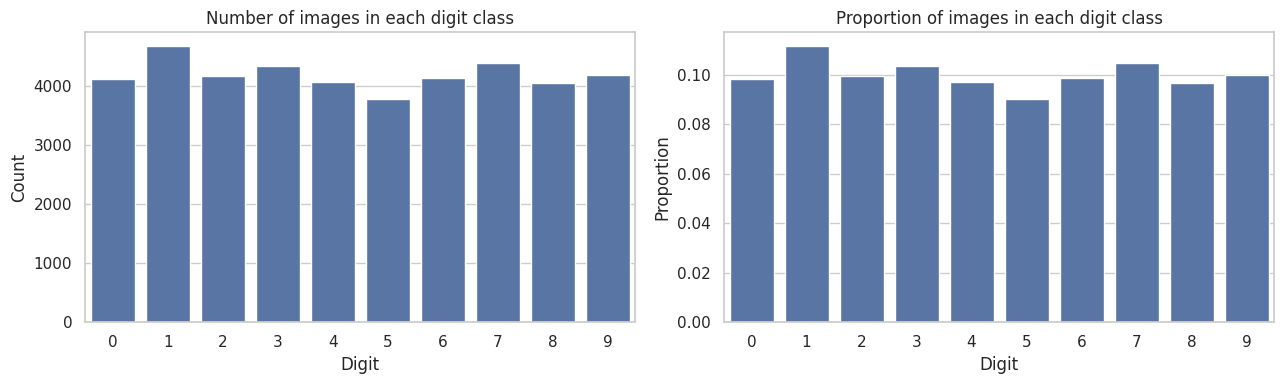

,count,proportion
label,,
0,4132,0.098381
1,4684,0.111524
2,4177,0.099452
3,4351,0.103595
4,4072,0.096952
5,3795,0.090357
6,4137,0.098500
7,4401,0.104786
8,4063,0.096738


In [9]:
class_counts = y.value_counts().sort_index()
class_proportions = y.value_counts(normalize=True).sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, ax=axes[0])
axes[0].set_title("Number of images in each digit class")
axes[0].set_xlabel("Digit")
axes[0].set_ylabel("Count")

sns.barplot(x=class_proportions.index, y=class_proportions.values, ax=axes[1])
axes[1].set_title("Proportion of images in each digit class")
axes[1].set_xlabel("Digit")
axes[1].set_ylabel("Proportion")
plt.tight_layout()
plt.show()

display(pd.DataFrame({"count": class_counts, "proportion": class_proportions}))

### 3.2 Visualise individual handwritten digits

The 784 columns are ordered pixel values. Reshaping one row into a 28 × 28 matrix reconstructs the image. This is a useful check that the data have been interpreted correctly.

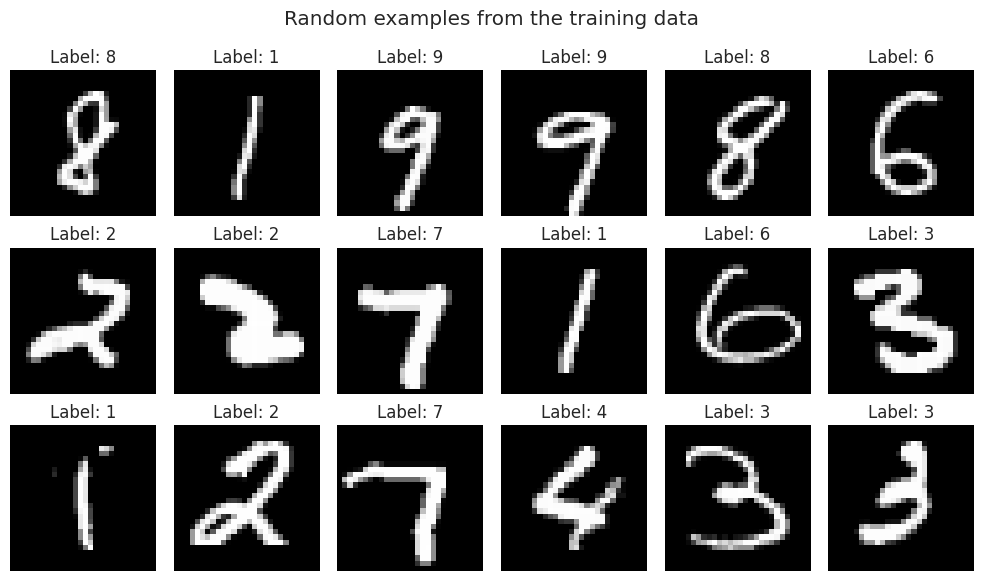

In [10]:
fig, axes = plt.subplots(3, 6, figsize=(10, 6))
sample_indices = np.random.choice(len(X), size=18, replace=False)

for ax, idx in zip(axes.ravel(), sample_indices):
    image = X.iloc[idx].to_numpy().reshape(28, 28)
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {y.iloc[idx]}")
    ax.axis("off")

plt.suptitle("Random examples from the training data")
plt.tight_layout()
plt.show()

### 3.3 Average image for each digit

Averaging all images within a class shows the typical spatial pattern for that digit. It is a descriptive summary, not a classifier.

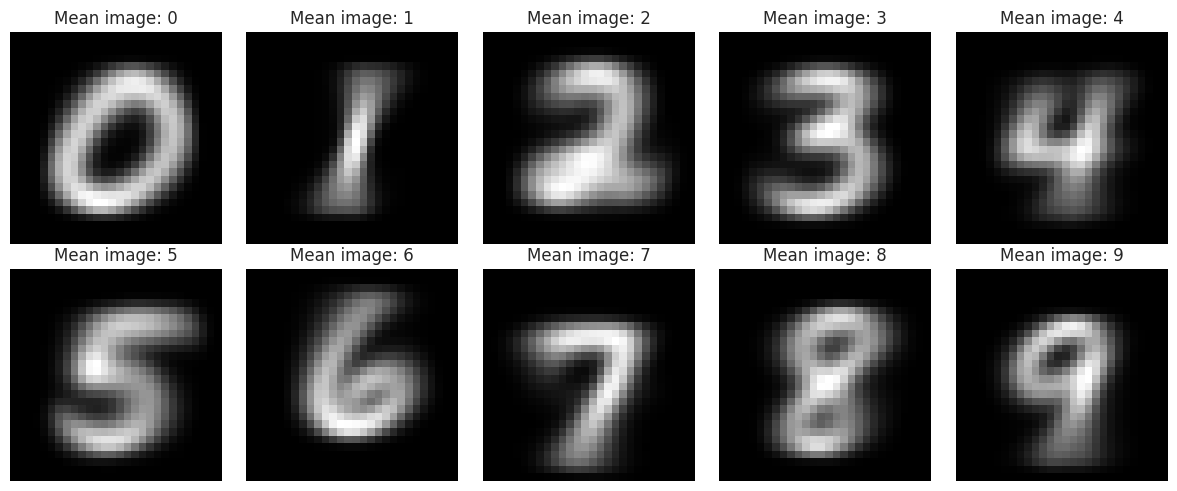

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for digit, ax in enumerate(axes.ravel()):
    mean_image = X.loc[y == digit].mean(axis=0).to_numpy().reshape(28, 28)
    ax.imshow(mean_image, cmap="gray")
    ax.set_title(f"Mean image: {digit}")
    ax.axis("off")
plt.tight_layout()
plt.show()

### 3.4 Pixel-intensity distribution and pixel variability

These plots help us understand the range of pixel values and identify pixels that are almost always blank. A pixel with zero variance contains no information for distinguishing observations.

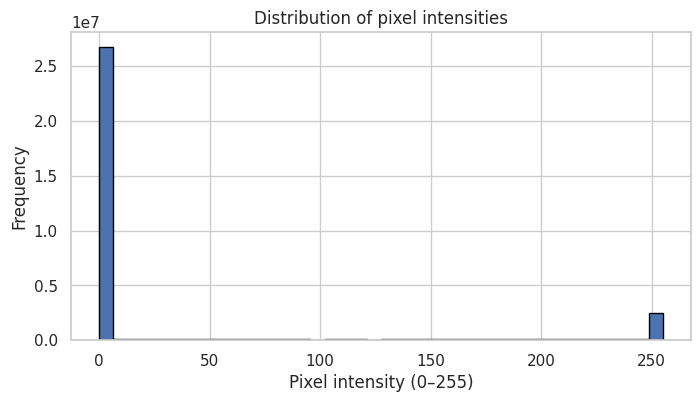

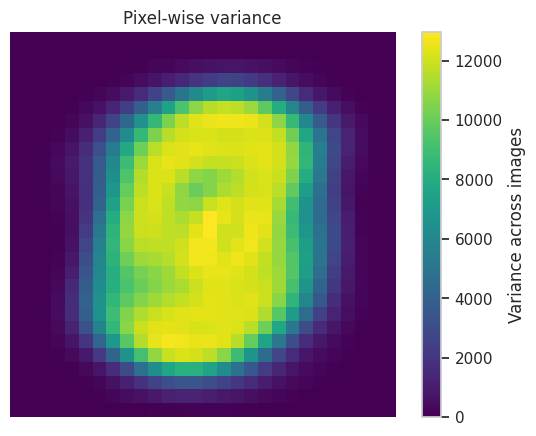

Number of zero-variance pixels: 76


In [12]:
pixel_values = X.to_numpy().ravel()
plt.figure(figsize=(8, 4))
plt.hist(pixel_values, bins=40, edgecolor="black")
plt.title("Distribution of pixel intensities")
plt.xlabel("Pixel intensity (0–255)")
plt.ylabel("Frequency")
plt.show()

pixel_variances = X.var(axis=0)
plt.figure(figsize=(7, 5))
plt.imshow(pixel_variances.to_numpy().reshape(28, 28), cmap="viridis")
plt.colorbar(label="Variance across images")
plt.title("Pixel-wise variance")
plt.axis("off")
plt.show()

print("Number of zero-variance pixels:", int((pixel_variances == 0).sum()))

### EDA interpretation prompts

Write a short paragraph in your project report answering:
1. Are all ten classes represented?
2. Does the class distribution look balanced?
3. What do the average digit images tell you?
4. Where is pixel variability concentrated?
5. What does the data-quality check suggest about missing values and duplicates?

Do not claim a pattern unless it is visible in your own notebook output.

## 4. Data preparation and validation design

We use a **stratified 80:20 split**. Stratification preserves approximately the same class proportions in the training and validation sets.

- `X_train`, `y_train`: used to fit models and tune hyperparameters.
- `X_valid`, `y_valid`: held aside for final comparison and diagnostics.
- `X_kaggle`: unlabeled competition data, not used for model selection.

The validation set is not used during cross-validation tuning. This makes it a final independent check after selecting a model.

In [13]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training subset:", X_train.shape)
print("Validation subset:", X_valid.shape)
print("\\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().round(3))
print("\\nValidation class proportions:")
display(y_valid.value_counts(normalize=True).sort_index().round(3))

Training subset: (33600, 784)
Validation subset: (8400, 784)
\nTraining class proportions:


,proportion
label,
0,0.098
1,0.112
2,0.099
3,0.104
4,0.097
5,0.090
6,0.099
7,0.105
8,0.097


\nValidation class proportions:


,proportion
label,
0,0.098
1,0.112
2,0.099
3,0.104
4,0.097
5,0.090
6,0.098
7,0.105
8,0.097


In [14]:
# Scale pixel values to [0, 1].
# This scaling is fixed and uses the known pixel range, so it does not estimate
# any parameter from validation observations.
X_train_scaled = X_train / 255.0
X_valid_scaled = X_valid / 255.0
X_kaggle_scaled = X_kaggle / 255.0

print("Scaled range:", X_train_scaled.to_numpy().min(),
      "to", X_train_scaled.to_numpy().max())

Scaled range: 0.0 to 1.0


## 5. Baseline model: majority-class prediction

Before using sophisticated models, we establish a simple benchmark. The `DummyClassifier` predicts the most frequent training class. A useful model should perform substantially better than this baseline.

This is a benchmark, not a serious handwritten-digit model.

In [15]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_valid)

baseline_accuracy = accuracy_score(y_valid, baseline_pred)
print(f"Majority-class baseline accuracy: {baseline_accuracy:.4f}")

Majority-class baseline accuracy: 0.1115


## 6. Fit and compare statistical learning classifiers

We begin with models that are directly connected to the course.

**Important:** model runtime depends on the Colab hardware. The SVM and k-NN sections can take longer than logistic regression or a tree model. If a cell is too slow, reduce the tuning sample size or use the suggested smaller grid.

### 6.1 Multinomial logistic regression

Multinomial logistic regression models class probabilities using a linear function of the predictors. It is a useful interpretable benchmark: coefficients indicate how pixel intensities relate to class log-odds, although interpreting 784 correlated pixels individually is difficult.

We use L2 regularisation to stabilise estimation when predictors are numerous and correlated. `C` is the inverse regularisation strength: smaller `C` means stronger regularisation.

In [16]:
logistic_model = LogisticRegression(
    C=1.0,
    penalty="l2",
    solver="lbfgs",
    max_iter=1000,
    random_state=RANDOM_STATE
)

start = time.time()
logistic_model.fit(X_train_scaled, y_train)
logistic_pred = logistic_model.predict(X_valid_scaled)
logistic_time = time.time() - start

print("Logistic regression accuracy:", accuracy_score(y_valid, logistic_pred))
print(f"Fit time: {logistic_time:.1f} seconds")

Logistic regression accuracy: 0.9129761904761905
Fit time: 74.5 seconds


### 6.2 Linear discriminant analysis (LDA)

LDA assumes that each class follows a multivariate normal distribution with a common covariance matrix. The resulting decision boundaries are linear.

There are many predictors relative to the number of observations per class, and the sample covariance matrix may be poorly conditioned. We therefore use the `lsqr` solver with shrinkage, which regularises covariance estimation.

In [17]:
lda_model = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")

start = time.time()
lda_model.fit(X_train_scaled, y_train)
lda_pred = lda_model.predict(X_valid_scaled)
lda_time = time.time() - start

print("LDA accuracy:", accuracy_score(y_valid, lda_pred))
print(f"Fit time: {lda_time:.1f} seconds")

LDA accuracy: 0.8730952380952381
Fit time: 4.6 seconds


## PCA

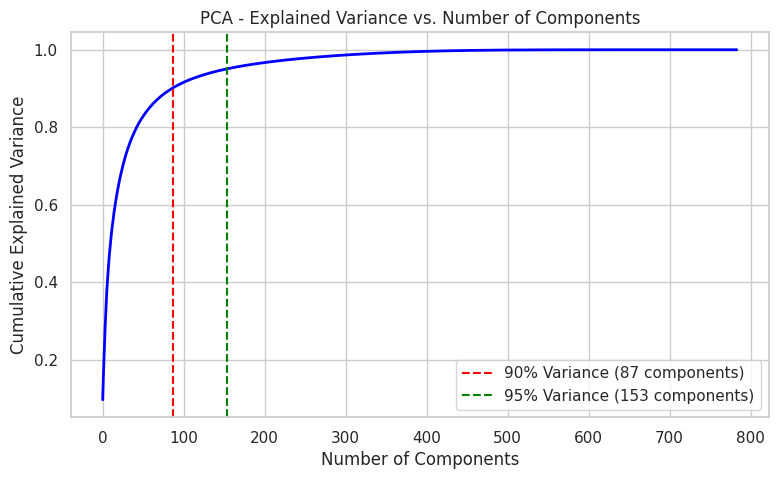

To retain 90% of variance: 87 components
To retain 95% of variance: 153 components

Shape after PCA transformation:
X_train_pca: (33600, 153)
X_valid_pca: (8400, 153)


In [18]:
from sklearn.decomposition import PCA

# 1. Fit PCA on the training set to find the optimal number of components
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_train_scaled)

cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

# Find the number of components required to retain 90% and 95% of the variance
n_90 = np.argmax(cumulative_variance >= 0.90) + 1
n_95 = np.argmax(cumulative_variance >= 0.95) + 1

# Plot the explained variance
plt.figure(figsize=(9, 5))
plt.plot(cumulative_variance, linewidth=2, color='blue')
plt.axvline(x=n_90, color='red', linestyle='--', label=f'90% Variance ({n_90} components)')
plt.axvline(x=n_95, color='green', linestyle='--', label=f'95% Variance ({n_95} components)')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - Explained Variance vs. Number of Components')
plt.legend()
plt.grid(True)
plt.show()

print(f"To retain 90% of variance: {n_90} components")
print(f"To retain 95% of variance: {n_95} components")

# 2. Project data onto the optimal number of components (using 95% variance as standard)
pca_opt = PCA(n_components=n_95, random_state=RANDOM_STATE)
X_train_pca = pca_opt.fit_transform(X_train_scaled)
X_valid_pca = pca_opt.transform(X_valid_scaled)
X_kaggle_pca = pca_opt.transform(X_kaggle_scaled)

print("\nShape after PCA transformation:")
print("X_train_pca:", X_train_pca.shape)
print("X_valid_pca:", X_valid_pca.shape)

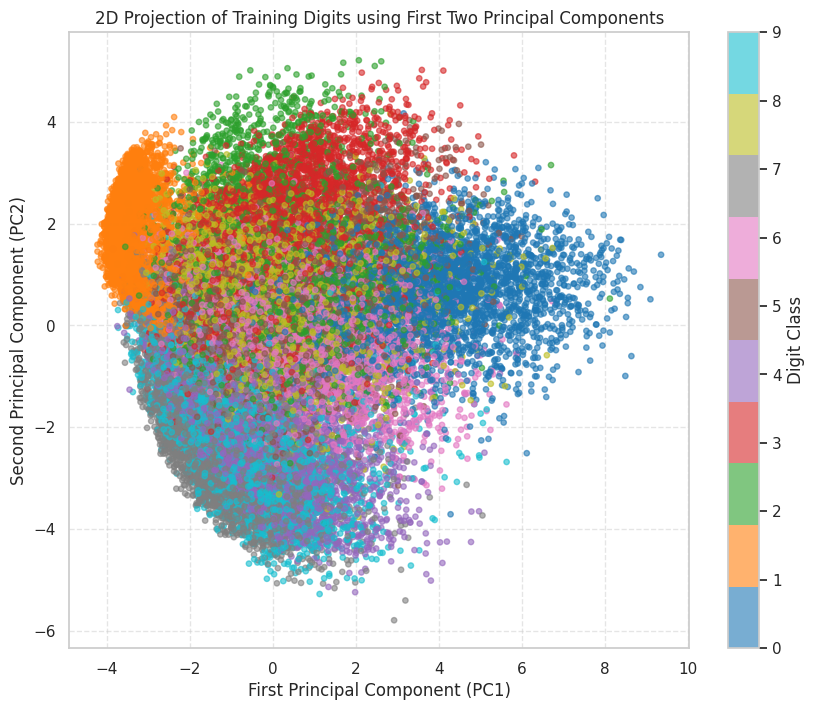

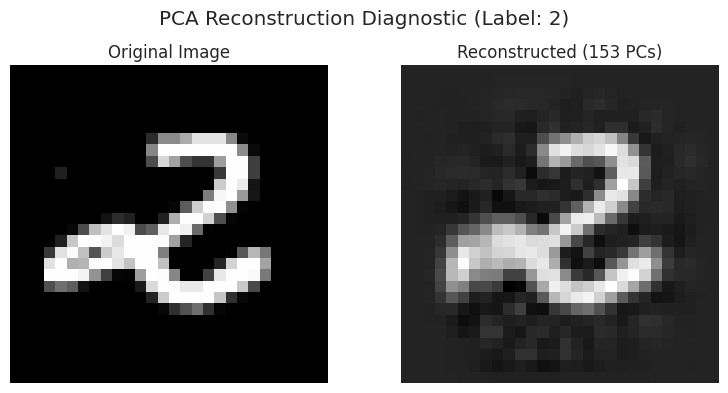

Variance explained by top 10 individual components:
  PC 1: 9.74%
  PC 2: 7.16%
  PC 3: 6.14%
  PC 4: 5.37%
  PC 5: 4.89%
  PC 6: 4.32%
  PC 7: 3.29%
  PC 8: 2.88%
  PC 9: 2.77%
  PC 10: 2.35%


In [19]:
# PCA Diagnostics
import matplotlib.pyplot as plt
import numpy as np

# 1. 2D projection visualization
plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='tab10', alpha=0.6, s=15)
plt.colorbar(scatter, label='Digit Class')
plt.xlabel('First Principal Component (PC1)')
plt.ylabel('Second Principal Component (PC2)')
plt.title('2D Projection of Training Digits using First Two Principal Components')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 2. Image Reconstruction Demo
sample_idx = 0
original_image = X_train_scaled.iloc[sample_idx].to_numpy().reshape(28, 28)

# Reconstruct using our selected optimal PCA components
reconstructed_flat = pca_opt.inverse_transform(X_train_pca[sample_idx])
reconstructed_image = reconstructed_flat.reshape(28, 28)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(original_image, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(reconstructed_image, cmap='gray')
axes[1].set_title(f'Reconstructed ({pca_opt.n_components_} PCs)')
axes[1].axis('off')

plt.suptitle(f'PCA Reconstruction Diagnostic (Label: {y_train.iloc[sample_idx]})')
plt.tight_layout()
plt.show()

# 3. Individual variance contribution of first few PCs
print("Variance explained by top 10 individual components:")
for i in range(10):
    print(f"  PC {i+1}: {pca_opt.explained_variance_ratio_[i]*100:.2f}%")

### 6.3 k-nearest neighbours (k-NN)

k-NN predicts the class based on the labels of nearby training observations. It is a nonparametric method.

- Small `k`: flexible boundary, potentially high variance.
- Large `k`: smoother boundary, potentially higher bias.

Pixel scaling is important because distance calculations are affected by feature scale. We use Euclidean distance as a starting point.

In [20]:
knn_model = KNeighborsClassifier(n_neighbors=5, weights="distance", n_jobs=-1)

start = time.time()
knn_model.fit(X_train_scaled, y_train)
knn_pred = knn_model.predict(X_valid_scaled)
knn_time = time.time() - start

print("k-NN accuracy:", accuracy_score(y_valid, knn_pred))
print(f"Fit time: {knn_time:.1f} seconds")

k-NN accuracy: 0.9677380952380953
Fit time: 23.6 seconds


### 6.4 CART decision tree

A classification tree recursively partitions the predictor space. Trees are easy to explain visually, but a deep tree can overfit. We first fit a deliberately unrestricted tree, then later tune its depth and minimum leaf size.

In [21]:
tree_model = DecisionTreeClassifier(random_state=RANDOM_STATE)

start = time.time()
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_valid)
tree_time = time.time() - start

print("Decision tree training accuracy:", tree_model.score(X_train, y_train))
print("Decision tree validation accuracy:", accuracy_score(y_valid, tree_pred))
print(f"Fit time: {tree_time:.1f} seconds")

Decision tree training accuracy: 1.0
Decision tree validation accuracy: 0.8551190476190477
Fit time: 12.8 seconds


### 6.5 Random forest: ensemble learning

A random forest averages many decision trees fitted on bootstrap samples and random subsets of predictors. This often reduces the variance of a single tree.

We use a moderate number of trees initially. Later, we tune tree complexity parameters. Random forests are less directly interpretable than a single tree, but provide feature-importance summaries.

In [22]:
rf_model = RandomForestClassifier(
    n_estimators=250,
    max_features="sqrt",
    min_samples_leaf=1,
    n_jobs=-1,
    random_state=RANDOM_STATE
)

start = time.time()
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_valid)
rf_time = time.time() - start

print("Random forest training accuracy:", rf_model.score(X_train, y_train))
print("Random forest validation accuracy:", accuracy_score(y_valid, rf_pred))
print(f"Fit time: {rf_time:.1f} seconds")

Random forest training accuracy: 1.0
Random forest validation accuracy: 0.965952380952381
Fit time: 56.6 seconds


### 6.6 Support vector machine (SVM)

An SVM seeks a separating boundary with a large margin. The RBF kernel allows nonlinear boundaries.

A full RBF SVM can be computationally demanding. We use PCA inside a pipeline to reduce the pixel dimension before fitting the RBF SVM. PCA is fitted within each training fold during cross-validation, avoiding leakage.

The number of principal components is a modelling choice; it should be treated as a tunable dimension-reduction parameter rather than a guaranteed optimum.

In [23]:
svm_model = Pipeline([
    ("pca", PCA(n_components=60, random_state=RANDOM_STATE)),
    ("svm", SVC(C=5.0, kernel="rbf", gamma="scale"))
])

# Kernel SVM training can require substantial memory. Fit it on a stratified
# subset of the training split, then evaluate on the full validation split.
SVM_N = min(8000, len(X_train_scaled))
X_svm, _, y_svm, _ = train_test_split(
    X_train_scaled, y_train,
    train_size=SVM_N,
    random_state=RANDOM_STATE,
    stratify=y_train
)

start = time.time()
svm_model.fit(X_svm, y_svm)
svm_pred = svm_model.predict(X_valid_scaled)
svm_time = time.time() - start

print("PCA + RBF SVM accuracy:", accuracy_score(y_valid, svm_pred))
print(f"Fit time: {svm_time:.1f} seconds")

PCA + RBF SVM accuracy: 0.9709523809523809
Fit time: 4.8 seconds


### 6.7 L1-penalised logistic regression (Lasso-style variable selection)

The L1 penalty can set some coefficients exactly to zero. This creates a sparse model and provides a variable-selection mechanism.

For a multiclass problem, the solver uses a multinomial objective with an L1 penalty. This is a useful connection to the syllabus topic on penalisation. Note that the selected pixels may be correlated, so individual selected coefficients should not be over-interpreted.

In [24]:
l1_logistic = LogisticRegression(
    C=0.15,
    penalty="l1",
    solver="saga",
    multi_class="multinomial",
    max_iter=1200,
    tol=0.002,
    random_state=RANDOM_STATE
)

start = time.time()
l1_logistic.fit(X_train_scaled, y_train)
l1_pred = l1_logistic.predict(X_valid_scaled)
l1_time = time.time() - start

print("L1 logistic validation accuracy:", accuracy_score(y_valid, l1_pred))
print(f"Fit time: {l1_time:.1f} seconds")

nonzero_coefficients = np.count_nonzero(l1_logistic.coef_)
total_coefficients = l1_logistic.coef_.size
print(f"Non-zero coefficients: {nonzero_coefficients:,} / {total_coefficients:,}")

L1 logistic validation accuracy: 0.9111904761904762
Fit time: 296.4 seconds
Non-zero coefficients: 1,585 / 7,840


## 7. Initial model comparison

We compare all fitted models on exactly the same validation observations. Accuracy is the competition's primary metric. Macro-F1 gives equal weight to each digit class and is useful if class frequencies differ.

A model's training accuracy is not enough: a very high training score combined with lower validation accuracy is evidence of overfitting.

,Model,Accuracy,Macro precision,Macro recall,Macro F1
5,PCA + RBF SVM,0.9710,0.9706,0.9706,0.9706
2,k-NN (k=5),0.9677,0.9684,0.9673,0.9675
4,Random forest,0.9660,0.9655,0.9656,0.9655
0,Logistic regression,0.9130,0.9121,0.9117,0.9118
6,L1 logistic,0.9112,0.9104,0.9099,0.9100
1,LDA (shrinkage),0.8731,0.8741,0.8715,0.8720
3,Decision tree,0.8551,0.8535,0.8535,0.8534


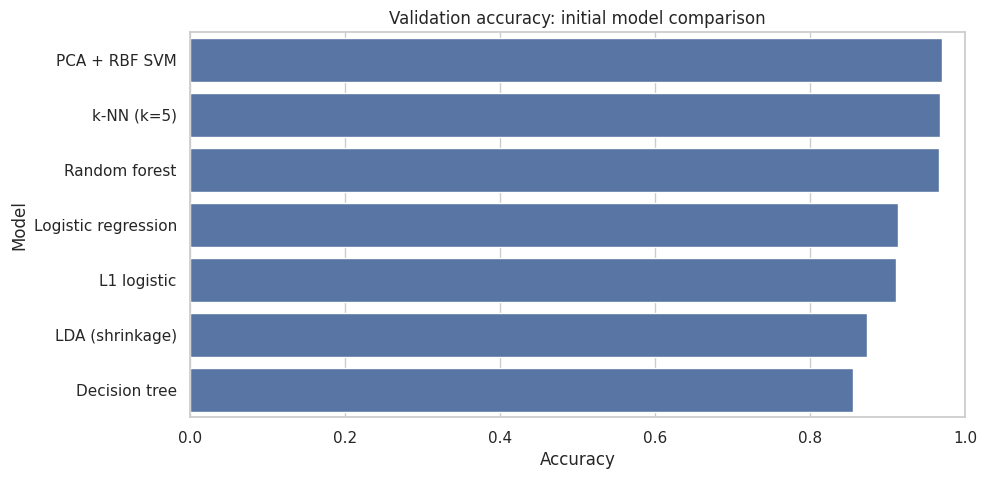

In [25]:
predictions = {
    "Logistic regression": logistic_pred,
    "LDA (shrinkage)": lda_pred,
    "k-NN (k=5)": knn_pred,
    "Decision tree": tree_pred,
    "Random forest": rf_pred,
    "PCA + RBF SVM": svm_pred,
    "L1 logistic": l1_pred
}

comparison_rows = []
for name, pred in predictions.items():
    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, pred),
        "Macro precision": precision_score(y_valid, pred, average="macro", zero_division=0),
        "Macro recall": recall_score(y_valid, pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_valid, pred, average="macro", zero_division=0)
    })

comparison = pd.DataFrame(comparison_rows).sort_values("Accuracy", ascending=False)
display(comparison.style.format({
    "Accuracy": "{:.4f}",
    "Macro precision": "{:.4f}",
    "Macro recall": "{:.4f}",
    "Macro F1": "{:.4f}"
}))

plt.figure(figsize=(10, 5))
sns.barplot(data=comparison, x="Accuracy", y="Model")
plt.xlim(0, 1)
plt.title("Validation accuracy: initial model comparison")
plt.show()

## 8. Model diagnostics

### 8.1 Confusion matrix for the best initial model

The confusion matrix counts true classes against predicted classes. The diagonal contains correct classifications. Off-diagonal entries show which digits are confused with one another.

We select the current best model by validation accuracy for diagnostic inspection. This is an initial comparison; the selected model may change after tuning.

Best initial model: PCA + RBF SVM


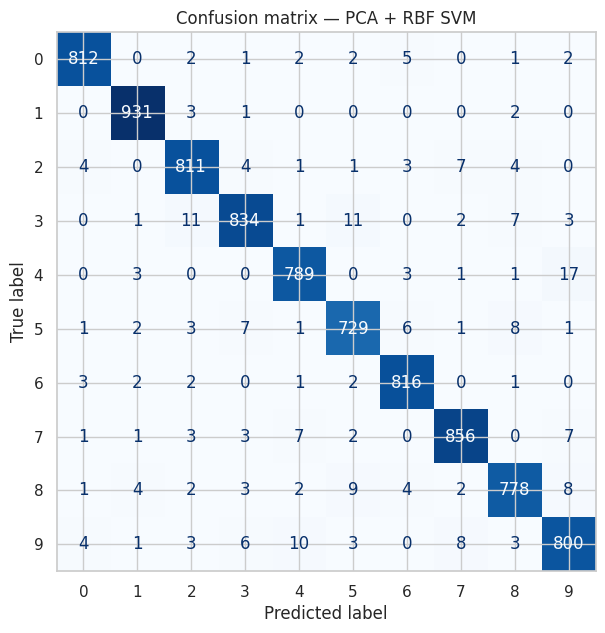

In [26]:
initial_best_name = comparison.iloc[0]["Model"]
initial_best_pred = predictions[initial_best_name]

print("Best initial model:", initial_best_name)
cm = confusion_matrix(y_valid, initial_best_pred, labels=np.arange(10))

fig, ax = plt.subplots(figsize=(9, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.arange(10))
disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
plt.title(f"Confusion matrix — {initial_best_name}")
plt.show()

### 8.2 Class-wise precision, recall and F1

- **Precision for digit d:** among images predicted as d, how many truly are d?
- **Recall for digit d:** among actual images of d, how many were detected?
- **F1-score:** harmonic mean of precision and recall.

A class with low recall is often confused with other digits. Use the report to identify classes needing closer inspection.

In [27]:
print(classification_report(
    y_valid,
    initial_best_pred,
    labels=np.arange(10),
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

           0     0.9831    0.9819    0.9825       827
           1     0.9852    0.9936    0.9894       937
           2     0.9655    0.9713    0.9684       835
           3     0.9709    0.9586    0.9647       870
           4     0.9693    0.9693    0.9693       814
           5     0.9605    0.9605    0.9605       759
           6     0.9749    0.9867    0.9808       827
           7     0.9761    0.9727    0.9744       880
           8     0.9665    0.9569    0.9617       813
           9     0.9547    0.9547    0.9547       838

    accuracy                         0.9710      8400
   macro avg     0.9706    0.9706    0.9706      8400
weighted avg     0.9709    0.9710    0.9709      8400



### 8.3 Inspect misclassified images

Looking at incorrect predictions can reveal whether errors are caused by ambiguous handwriting, similar digit shapes or systematic model weaknesses. This is qualitative diagnosis; do not manually relabel validation examples to improve the score.

Number of validation errors: 244


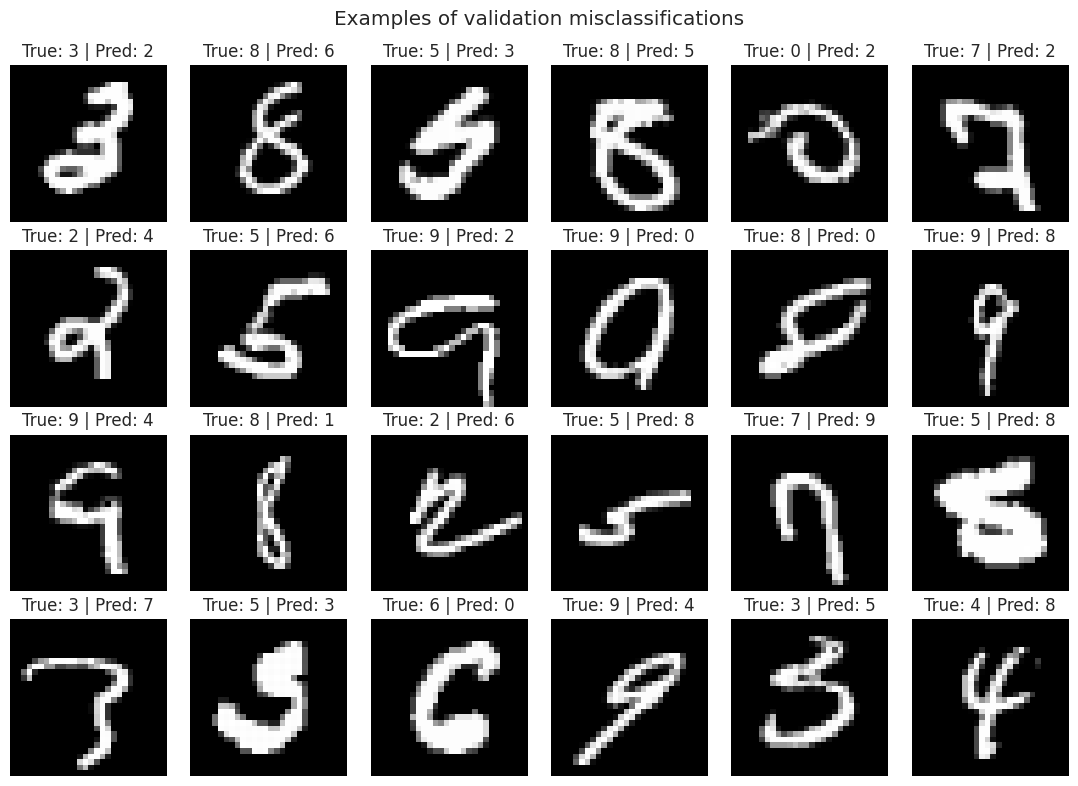

In [28]:
wrong_positions = np.flatnonzero(initial_best_pred != y_valid.to_numpy())
print("Number of validation errors:", len(wrong_positions))

n_show = min(24, len(wrong_positions))
if n_show > 0:
    chosen_wrong = np.random.choice(wrong_positions, size=n_show, replace=False)
    fig, axes = plt.subplots(4, 6, figsize=(11, 8))
    for ax, pos in zip(axes.ravel(), chosen_wrong):
        ax.imshow(X_valid.iloc[pos].to_numpy().reshape(28, 28), cmap="gray")
        ax.set_title(f"True: {y_valid.iloc[pos]} | Pred: {initial_best_pred[pos]}")
        ax.axis("off")
    for ax in axes.ravel()[n_show:]:
        ax.axis("off")
    plt.suptitle("Examples of validation misclassifications")
    plt.tight_layout()
    plt.show()

## 9. Model selection and hyperparameter tuning

The goal of model selection is not to find the most complicated model. It is to choose a model whose expected prediction error on new data is low.

We use **stratified 3-fold cross-validation** on the training split. Each candidate is fitted on two folds and evaluated on the remaining fold; this is repeated so each fold is used for validation once.

For practical runtime, the next cell creates a stratified tuning subset. The final selected configuration is then evaluated once on the untouched validation set. If Colab has sufficient resources, increase `TUNE_N` or use 5-fold CV.

In [29]:
TUNE_N = min(10000, len(X_train))
X_tune, _, y_tune, _ = train_test_split(
    X_train, y_train,
    train_size=TUNE_N,
    random_state=RANDOM_STATE,
    stratify=y_train
)

X_tune_scaled = X_tune / 255.0

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
print("Tuning sample:", X_tune.shape)

Tuning sample: (10000, 784)


### 9.1 Tune logistic regression regularisation

The parameter `C` controls the strength of L2 regularisation. We choose it using cross-validation accuracy.

In [30]:
logistic_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(
        solver="lbfgs", max_iter=1200, random_state=RANDOM_STATE
    ))
])

# Since pixel columns are all on the same 0–255 scale, the explicit /255
# transformation is already useful. StandardScaler here additionally centres
# and scales each pixel using only the training fold.
logistic_grid = {
    "model__C": [0.01, 0.1, 1.0, 5.0]
}

logistic_search = GridSearchCV(
    logistic_pipe, logistic_grid,
    scoring="accuracy", cv=cv, n_jobs=-1, verbose=1
)
logistic_search.fit(X_tune, y_tune)

print("Best logistic parameters:", logistic_search.best_params_)
print("Best CV accuracy:", logistic_search.best_score_)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best logistic parameters: {'model__C': 0.01}
Best CV accuracy: 0.9083994782201676


### 9.2 Tune k-NN neighbourhood size

We compare a small set of `k` values. The value of `k` controls the smoothness of the decision rule. We use uniform voting in this grid to keep the comparison simple.

In [31]:
knn_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier(n_jobs=-1))
])

knn_grid = {
    "model__n_neighbors": [3, 5, 7, 11],
    "model__weights": ["uniform", "distance"]
}

knn_search = GridSearchCV(
    knn_pipe, knn_grid,
    scoring="accuracy", cv=cv, n_jobs=-1, verbose=1
)
knn_search.fit(X_tune, y_tune)

print("Best k-NN parameters:", knn_search.best_params_)
print("Best CV accuracy:", knn_search.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best k-NN parameters: {'model__n_neighbors': 5, 'model__weights': 'distance'}
Best CV accuracy: 0.9081001081511869


### 9.3 Tune decision-tree complexity

`max_depth` limits tree depth and `min_samples_leaf` requires a minimum number of observations in each terminal node. These parameters control complexity and help reduce overfitting.

In [32]:
tree_grid = {
    "max_depth": [10, 20, None],
    "min_samples_leaf": [1, 3, 8]
}

tree_search = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    tree_grid,
    scoring="accuracy", cv=cv, n_jobs=-1, verbose=1
)
tree_search.fit(X_tune, y_tune)

print("Best tree parameters:", tree_search.best_params_)
print("Best CV accuracy:", tree_search.best_score_)

Fitting 3 folds for each of 9 candidates, totalling 27 fits
Best tree parameters: {'max_depth': 20, 'min_samples_leaf': 3}
Best CV accuracy: 0.7956994859653932


### 9.4 Tune random forest complexity

We vary the number of candidate predictors at each split, the minimum leaf size and the number of trees. More trees can stabilise predictions but increase computation.

In [34]:
rf_grid = {
    "n_estimators": [200, 350],
    "max_features": ["sqrt", 0.25],
    "min_samples_leaf": [1, 2, 4],
    "max_depth": [None, 25]
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(
        n_jobs=-1, random_state=RANDOM_STATE
    ),
    param_distributions=rf_grid,
    n_iter=8,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1
)
rf_search.fit(X_tune, y_tune)

print("Best random forest parameters:", rf_search.best_params_)
print("Best CV accuracy:", rf_search.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best random forest parameters: {'n_estimators': 350, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 25}
Best CV accuracy: 0.946899758962099


### 9.5 Compare cross-validation results

Cross-validation scores are used for tuning, while the held-out validation set is used for the final comparison. A small difference between CV and validation performance is expected. A large gap may indicate instability or overfitting.

In [35]:
tuning_summary = pd.DataFrame([
    {"Model": "Logistic regression", "Best CV accuracy": logistic_search.best_score_},
    {"Model": "k-NN", "Best CV accuracy": knn_search.best_score_},
    {"Model": "Decision tree", "Best CV accuracy": tree_search.best_score_},
    {"Model": "Random forest", "Best CV accuracy": rf_search.best_score_}
]).sort_values("Best CV accuracy", ascending=False)

display(tuning_summary.style.format({"Best CV accuracy": "{:.4f}"}))

,Model,Best CV accuracy
3,Random forest,0.9469
0,Logistic regression,0.9084
1,k-NN,0.9081
2,Decision tree,0.7957


## 10. Final validation comparison after tuning

We now evaluate each tuned estimator on the held-out validation set. The validation set has not been used in cross-validation tuning.

**Important distinction:** the best CV score is not the final reported generalisation estimate. The held-out validation score is the main estimate to report here.

In [36]:
tuned_estimators = {
    "Tuned logistic regression": logistic_search.best_estimator_,
    "Tuned k-NN": knn_search.best_estimator_,
    "Tuned decision tree": tree_search.best_estimator_,
    "Tuned random forest": rf_search.best_estimator_
}

tuned_predictions = {}
tuned_rows = []

for name, estimator in tuned_estimators.items():
    pred = estimator.predict(X_valid)
    tuned_predictions[name] = pred
    tuned_rows.append({
        "Model": name,
        "Validation accuracy": accuracy_score(y_valid, pred),
        "Macro F1": f1_score(y_valid, pred, average="macro")
    })

tuned_comparison = pd.DataFrame(tuned_rows).sort_values(
    "Validation accuracy", ascending=False
)
display(tuned_comparison.style.format({
    "Validation accuracy": "{:.4f}",
    "Macro F1": "{:.4f}"
}))

,Model,Validation accuracy,Macro F1
3,Tuned random forest,0.9525,0.9520
1,Tuned k-NN,0.9130,0.9121
0,Tuned logistic regression,0.9082,0.9070
2,Tuned decision tree,0.8118,0.8089


## 11. Bias–variance and overfitting diagnostics

A flexible model can fit training observations extremely well but generalise less well. We compare training and validation accuracy for selected models.

- **Large training score, much lower validation score:** possible overfitting/high variance.
- **Both scores low:** possible underfitting/high bias.
- **Both scores high and close:** good fit and generalisation on this split.

The gap is a diagnostic, not a formal decomposition of prediction error into bias and variance.

In [37]:
diagnostic_models = {
    "Decision tree": tree_model,
    "Random forest": rf_model,
    "Logistic regression": logistic_model,
    "LDA": lda_model,
    "PCA + RBF SVM": svm_model
}

gap_rows = []
for name, model in diagnostic_models.items():
    if name in ["Logistic regression", "LDA", "PCA + RBF SVM"]:
        train_score = model.score(X_train_scaled, y_train)
        valid_score = model.score(X_valid_scaled, y_valid)
    else:
        train_score = model.score(X_train, y_train)
        valid_score = model.score(X_valid, y_valid)

    gap_rows.append({
        "Model": name,
        "Training accuracy": train_score,
        "Validation accuracy": valid_score,
        "Train-validation gap": train_score - valid_score
    })

gap_table = pd.DataFrame(gap_rows).sort_values("Validation accuracy", ascending=False)
display(gap_table.style.format({
    "Training accuracy": "{:.4f}",
    "Validation accuracy": "{:.4f}",
    "Train-validation gap": "{:.4f}"
}))

,Model,Training accuracy,Validation accuracy,Train-validation gap
4,PCA + RBF SVM,0.9782,0.9710,0.0073
1,Random forest,1.0000,0.9660,0.0340
2,Logistic regression,0.9460,0.9130,0.0330
3,LDA,0.8785,0.8731,0.0054
0,Decision tree,1.0000,0.8551,0.1449


### 11.1 Learning curve

A learning curve shows how training and cross-validation performance change as the training sample size increases. If validation performance is still improving substantially at the largest sample size, more data may help. If the curves remain far apart, variance may be an issue; if both are poor and close, the model may be too simple.

This cell uses a moderate sample and 3-fold CV to keep runtime manageable.

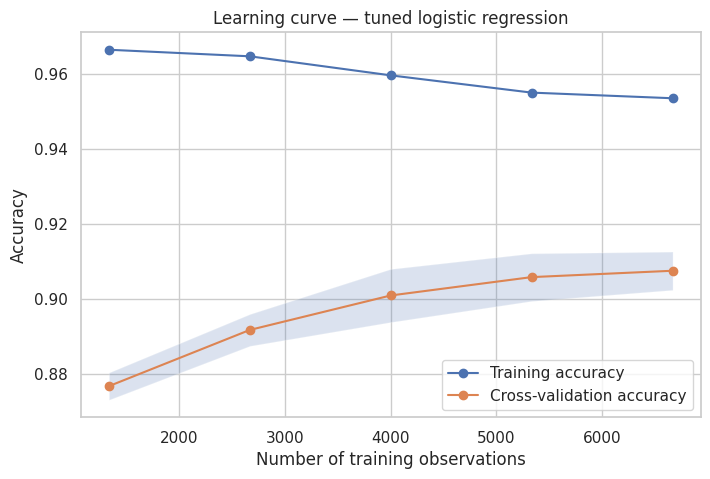

In [38]:
learning_estimator = logistic_search.best_estimator_

train_sizes, train_scores, cv_scores = learning_curve(
    learning_estimator,
    X_tune,
    y_tune,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    shuffle=True,
    random_state=RANDOM_STATE
)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_scores.mean(axis=1), marker="o", label="Training accuracy")
plt.plot(train_sizes, cv_scores.mean(axis=1), marker="o", label="Cross-validation accuracy")
plt.fill_between(
    train_sizes,
    cv_scores.mean(axis=1) - cv_scores.std(axis=1),
    cv_scores.mean(axis=1) + cv_scores.std(axis=1),
    alpha=0.2
)
plt.xlabel("Number of training observations")
plt.ylabel("Accuracy")
plt.title("Learning curve — tuned logistic regression")
plt.legend()
plt.show()

## 12. Feature interpretation

For a linear classifier, coefficients describe how each pixel contributes to class scores. Because neighbouring pixels are correlated, coefficients should be interpreted as a joint pattern rather than isolated causal effects.

For random forests, impurity-based feature importance measures how much a pixel contributes to reductions in node impurity. It can be biased toward certain predictor types and should be treated as descriptive rather than causal.

Top 15 pixels by random-forest impurity importance:


,importance
pixel378,0.009578
pixel350,0.008724
pixel433,0.008241
pixel405,0.007993
pixel377,0.007428
pixel461,0.007405
pixel409,0.007173
pixel514,0.006934
pixel406,0.006830
pixel489,0.006824


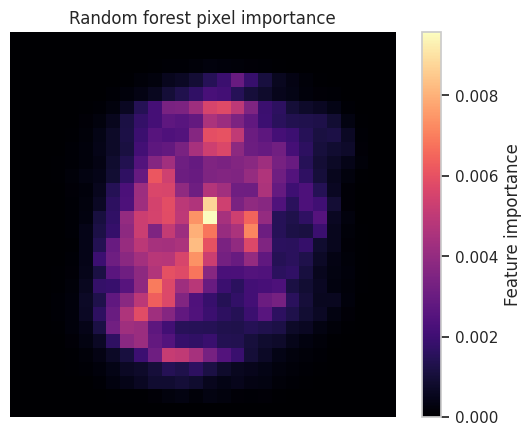

In [39]:
# Random forest pixel importance map
rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Top 15 pixels by random-forest impurity importance:")
display(rf_importance.head(15).to_frame("importance"))

plt.figure(figsize=(7, 5))
plt.imshow(rf_model.feature_importances_.reshape(28, 28), cmap="magma")
plt.colorbar(label="Feature importance")
plt.title("Random forest pixel importance")
plt.axis("off")
plt.show()

## 13. Select the final model

The next cell chooses the best tuned estimator by **held-out validation accuracy**. If two models have very similar accuracy, also consider macro-F1, computational cost, stability and interpretability. The automatically selected winner is a starting point; document your reasoning in the report.

In [40]:
best_tuned_name = tuned_comparison.iloc[0]["Model"]
best_tuned_model = tuned_estimators[best_tuned_name]

print("Selected model:", best_tuned_name)
print("Held-out validation accuracy:",
      accuracy_score(y_valid, tuned_predictions[best_tuned_name]))
print("Held-out validation macro-F1:",
      f1_score(y_valid, tuned_predictions[best_tuned_name], average="macro"))

Selected model: Tuned random forest
Held-out validation accuracy: 0.9525
Held-out validation macro-F1: 0.9520262689023692


## 14. Final diagnostics for the selected model

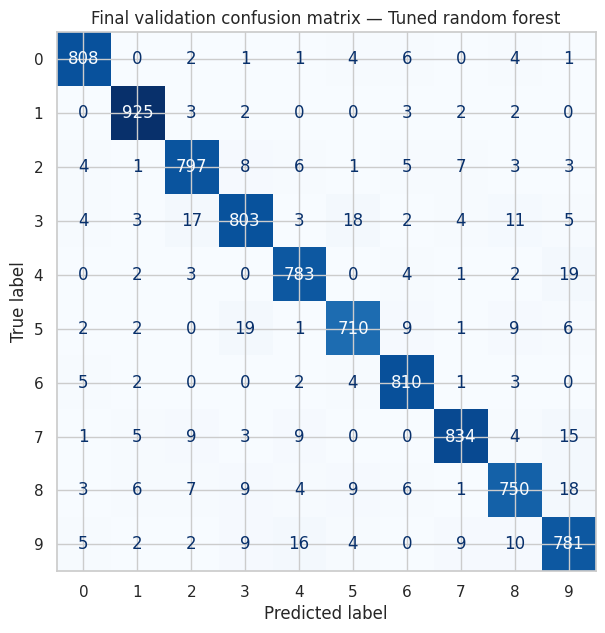

              precision    recall  f1-score   support

           0     0.9712    0.9770    0.9741       827
           1     0.9757    0.9872    0.9814       937
           2     0.9488    0.9545    0.9516       835
           3     0.9403    0.9230    0.9316       870
           4     0.9491    0.9619    0.9555       814
           5     0.9467    0.9354    0.9410       759
           6     0.9586    0.9794    0.9689       827
           7     0.9698    0.9477    0.9586       880
           8     0.9398    0.9225    0.9311       813
           9     0.9210    0.9320    0.9265       838

    accuracy                         0.9525      8400
   macro avg     0.9521    0.9521    0.9520      8400
weighted avg     0.9525    0.9525    0.9524      8400



In [41]:
final_valid_pred = best_tuned_model.predict(X_valid)

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(
    confusion_matrix(y_valid, final_valid_pred, labels=np.arange(10)),
    display_labels=np.arange(10)
).plot(ax=ax, cmap="Blues", colorbar=False)
plt.title(f"Final validation confusion matrix — {best_tuned_name}")
plt.show()

print(classification_report(
    y_valid, final_valid_pred,
    labels=np.arange(10), digits=4, zero_division=0
))

## 15. Refit the selected model on all labelled observations

After all modelling decisions have been made using the training split and validation set, we can refit the selected model using all 42,000 labelled examples. This uses more labelled information for the final competition predictions.

The validation score remains the performance estimate to report. Do not report the accuracy on `test.csv`: its labels are not supplied.

In [42]:
# Refit the chosen tuned estimator on all labelled data.
best_tuned_model.fit(X, y)

# Predict the 28,000 Kaggle test observations.
kaggle_predictions = best_tuned_model.predict(X_kaggle)

print("Number of Kaggle predictions:", len(kaggle_predictions))
print("Predicted classes:", np.unique(kaggle_predictions))

Number of Kaggle predictions: 28000
Predicted classes: [0 1 2 3 4 5 6 7 8 9]


## Predict a digit from your own handwritten image

In [49]:

# # Upload one handwritten digit image (PNG, JPG or JPEG).
# from google.colab import files
# from PIL import Image
# import io
# import numpy as np
# import matplotlib.pyplot as plt

# uploaded_digit = files.upload()
# if not uploaded_digit:
#     raise ValueError("Please upload an image containing one handwritten digit.")

# image_name = next(iter(uploaded_digit))
# original_image = Image.open(io.BytesIO(uploaded_digit[image_name])).convert("L")

# print("Uploaded:", image_name)
# display(original_image)


### Preprocess the uploaded image

In [50]:

# def prepare_handwritten_digit(pil_image):
#     img = pil_image.convert("L")
#     arr = np.asarray(img).astype(np.uint8)

#     # If the border is mostly bright, assume a white-paper background and invert.
#     border = np.concatenate([arr[0, :], arr[-1, :], arr[:, 0], arr[:, -1]])
#     if border.mean() > 127:
#         arr = 255 - arr

#     img = Image.fromarray(arr)

#     # Crop around the visible writing.
#     mask = np.asarray(img) > 25
#     if mask.any():
#         rows = np.where(mask.any(axis=1))[0]
#         cols = np.where(mask.any(axis=0))[0]
#         img = img.crop((cols[0], rows[0], cols[-1] + 1, rows[-1] + 1))

#     # Resize while preserving aspect ratio, then centre in a 28 x 28 image.
#     img.thumbnail((20, 20), Image.Resampling.LANCZOS)
#     canvas = Image.new("L", (28, 28), color=0)
#     canvas.paste(img, ((28 - img.width) // 2, (28 - img.height) // 2))

#     return np.asarray(canvas).astype("float32"), canvas

# user_pixels, processed_image = prepare_handwritten_digit(original_image)

# plt.figure(figsize=(3, 3))
# plt.imshow(processed_image, cmap="gray", vmin=0, vmax=255)
# plt.title("28 × 28 image given to the model")
# plt.axis("off")
# plt.show()


## Predict the handwritten digit

In [51]:

# # Convert one 28 x 28 image into one row with the same 784 columns as X.
# user_row = pd.DataFrame(user_pixels.reshape(1, 784), columns=X.columns)

# predicted_digit = int(best_tuned_model.predict(user_row)[0])

# print("===================================")
# print(f"       PREDICTED DIGIT: {predicted_digit}")
# print("===================================")

# # Display estimated class probabilities if this estimator supports them.
# if hasattr(best_tuned_model, "predict_proba"):
#     probabilities = best_tuned_model.predict_proba(user_row)[0]
#     probability_table = pd.DataFrame({
#         "Digit": best_tuned_model.classes_.astype(int),
#         "Estimated probability": probabilities
#     }).sort_values("Estimated probability", ascending=False)

#     display(probability_table.style.format({
#         "Estimated probability": "{:.2%}"
#     }))

#     plt.figure(figsize=(8, 3))
#     plt.bar(probability_table["Digit"].astype(str),
#             probability_table["Estimated probability"])
#     plt.xlabel("Digit")
#     plt.ylabel("Estimated probability")
#     plt.title("Model probability estimates")
#     plt.show()
# else:
#     print("The selected model does not provide class probabilities.")


In [52]:
# # Diagnostic: Let's inspect the scale and contents of the user's preprocessed pixels
# print("=== User Image Diagnostics ===")
# print("User pixels min:", user_pixels.min())
# print("User pixels max:", user_pixels.max())
# print("User pixels mean:", user_pixels.mean())

# print("\n=== Training Data (X) Diagnostics ===")
# print("Training pixels min:", X.to_numpy().min())
# print("Training pixels max:", X.to_numpy().max())

# # Check if there is a scaling mismatch (e.g. model expects 0-255 but gets 0-1, or vice-versa)
# if X_train.to_numpy().max() > 1.0 and user_pixels.max() <= 1.0:
#     print("\n[!] FAULT DETECTED: Scaling Mismatch. The model was trained on 0-255 pixels, but your image is scaled between 0 and 1.0.")
# elif X_train.to_numpy().max() <= 1.0 and user_pixels.max() > 1.0:
#     print("\n[!] FAULT DETECTED: Scaling Mismatch. The model was trained on 0-1 pixels, but your image is scaled between 0 and 255.")
# else:
#     print("\n[+] No scaling mismatch detected. Checking background color correctness...")

# # Let's inspect the border pixels to see if the background inversion worked correctly
# border_mean = np.concatenate([user_pixels[0, :], user_pixels[-1, :], user_pixels[:, 0], user_pixels[:, -1]]).mean()
# print(f"User image average border intensity: {border_mean:.2f} (Should be close to 0)")

## 17. Optional extensions from the syllabus

These are extensions, not requirements for the first complete version. Add them only after the core notebook runs successfully.

1. **Quadratic discriminant analysis (QDA):** allows a separate covariance matrix for each class. With 784 predictors, covariance estimation can be unstable; dimension reduction or regularisation is needed.
2. **Linear SVM:** compare a linear margin classifier against the RBF kernel SVM.
3. **PCA before classification:** compare accuracy and runtime at several component counts, such as 30, 60, 100 and 150.
4. **Soft-voting ensemble:** combine probability estimates from well-performing, complementary classifiers. Compare it with the best single model on the same validation set.
5. **Neural network:** a small multilayer perceptron trained on flattened pixels connects to the neural-network section of the syllabus. Keep it as an extension so the main analysis remains focused on classical statistical learning.
6. **Calibration:** assess whether predicted class probabilities are reliable, not just whether the most likely class is correct.

Do not add every method just to increase the number of algorithms. A careful comparison and a well-explained selection are more valuable.